# Virtual iEEG

The work by [Grova et al. (2016)](https://onlinelibrary.wiley.com/doi/epdf/10.1002/hbm.23127) describes a methodology to compare source reconstruction with intracranial EEG and to evaluate source reconstruction in vivo. The authors project the source-reconstructed data, using a simplified forward model, onto the channel positions of the iEEG. They then compute four metrics to quantitatively evaluate the reconstruction:

1. Spatial correlation
2. Euclidean distance between maxima
3. Spatial dispersion
4. Ratio of spurious activity

This notebook implements the method proposed by Grova et al. on other datasets.

## 🧪 - Experiment setup
- `src`: Source spaces
- `i-ave`: Average intracranial recording
- `wcset`: Source estimate using wCSET method
- `sloreta`: Source estimate using sLORETA method

In [1]:
# imports
import mindmap as mm

# reader
dm = mm.io.TutoManager("../../config.yml")
sr = dm.get_subject("intra-12")

# data
src = sr.load("src")
ieeg = sr.load("i-ave", task="spk")
wcset = sr.load("stc", desc="wcset")
sloreta = sr.load("stc", desc="sloreta")

## 🧬 - Data Processing
Estimate spike generation extent and spurious areas
`extent_mask`: Mask of channels in spike extent area.
`spurious_mask`: Mask for channels in spurious area.

In [2]:
# estimate spike generation extent zone and spurious zone
extent_mask = mm.core.get_spike_extent_mask(
    ieeg.data.T, 
    perc_max_amp=0.7
)

spurious_mask = mm.core.get_spurious_mask(
    extent_mask,
    mm.analysis.eeg.get_ch_positions(ieeg),
    spurious_dist=0.01
)

Virtual electrodes: Project source reconstruction to iEEG channel positions.
`v_wcset`: virtual electrodes estimated using wCSET output
`v_sloreta`: virtual electrodes estimated using sLORETA output

In [3]:
v_wcset = mm.analysis.eeg.compute_virtual_ieeg(
    src,
    wcset,
    ieeg,
    conductivity = 0.25,
    threshold = 0.003,
)

v_sloreta = mm.analysis.eeg.compute_virtual_ieeg(
    src,
    sloreta,
    ieeg,
    conductivity = 0.25,
    threshold = 0.003,
)

Compute metrics from Grova et. al.

In [4]:
# normalize data for visualizations
ieeg_norm = mm.analysis.eeg.normalize_evoked(ieeg, "global", "zscore")
v_wcset_norm = mm.analysis.eeg.normalize_evoked(v_wcset, "global", "zscore")
v_sloreta_norm = mm.analysis.eeg.normalize_evoked(v_sloreta, "global", "zscore")

metrics_wcset = mm.analysis.eeg.compute_grova_metrics(
    ieeg_norm,
    v_wcset_norm,
    true_extent = 0.7,
    spurious_dist = 0.01,
)

metrics_sloreta = mm.analysis.eeg.compute_grova_metrics(
    ieeg_norm,
    v_sloreta_norm,
    true_extent = 0.7,
    spurious_dist = 0.01,
)

## 📊 - Visualization
Channel position

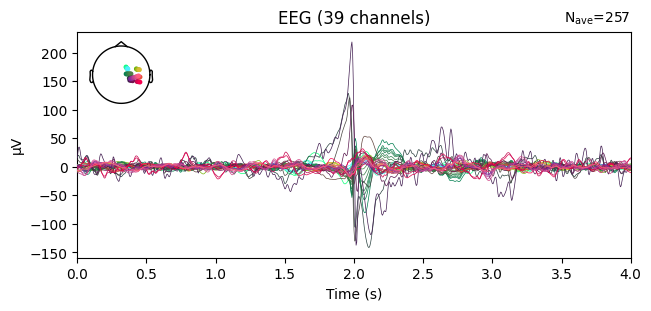

In [6]:
ieeg.plot();

In [7]:
mm.viz.plot_ieeg(src, ieeg, extent_mask, spurious_mask, subject = sr.sub).show()

Widget(value='<iframe src="http://localhost:33327/index.html?ui=P_0x797df1028f50_0&reconnect=auto" class="pyvi…

Global field power

/tmp/ipykernel_85757/43824775.py:8: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  ).show()


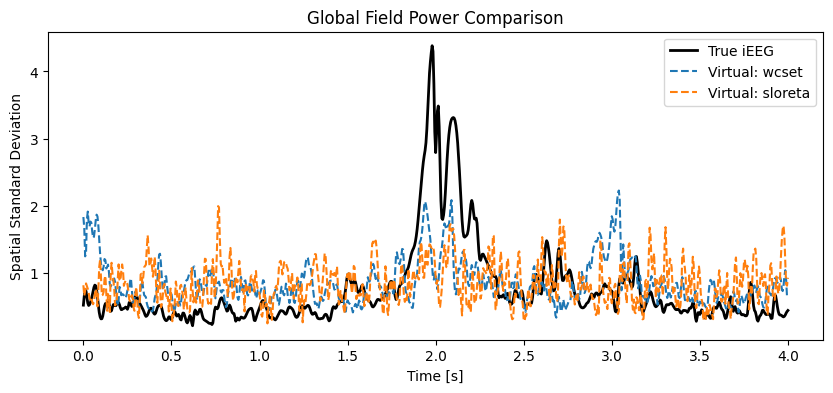

In [8]:
# plot the global field power (gfp)
mm.viz.plot_gfp_comparison(
    ieeg_norm,
    dict_of_evoked_est = {
        "wcset": v_wcset_norm,
        "sloreta": v_sloreta_norm,
    }
).show()

Individual averaged channels

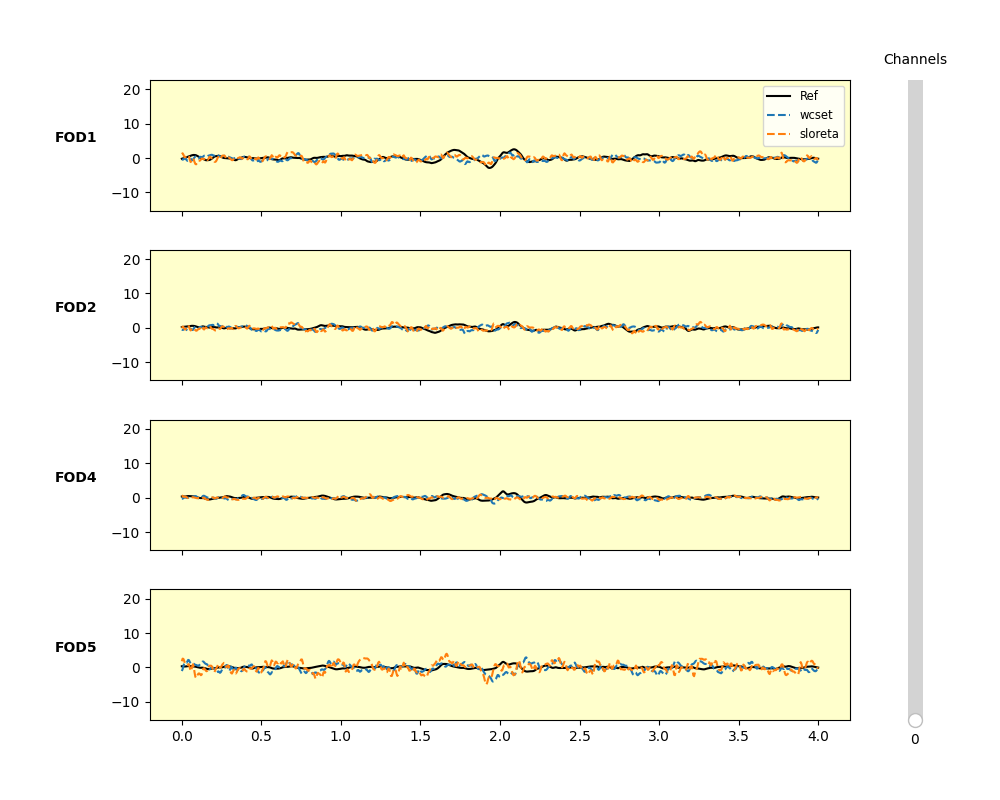

In [9]:
%matplotlib widget


# plot individual channels
_ = mm.viz.plot_channel_grid(ieeg_norm, {"wcset":v_wcset_norm, "sloreta":v_sloreta_norm}, extent_mask, spurious_mask)


In [10]:
mm.viz.plot_source_estimate(src, [wcset, sloreta], ts_params={"normalize":"robust", "absolute":True}).show()

Widget(value='<iframe src="http://localhost:33327/index.html?ui=P_0x797dd8823150_1&reconnect=auto" class="pyvi…

Grova metrics

In [5]:
metrics_wcset

{'spatial_correlation': np.float64(0.12518736750966689),
 'min_distance': np.float32(0.03782162),
 'spatial_dispersion': np.float64(0.19457408469629955),
 'ratio_spurious': np.float64(0.9824056288059172)}

In [11]:
metrics_sloreta

{'subject': Ellipsis,
 'method': Ellipsis,
 'spatial_correlation': np.float64(0.24974340872892542),
 'min_distance': np.float32(0.03782162),
 'spatial_dispersion': np.float64(0.19503885581385255),
 'ratio_spurious': np.float64(0.9479148839260118)}

In [9]:
import pandas as pd

method_a = {'accuracy': 0.92, 'f1_score': 0.88, 'latency': 120}
method_b = {'accuracy': 0.95, 'f1_score': 0.91, 'latency': 150}

# 1. Combine into a single dictionary
data = {'Method A': method_a, 'Method B': method_b}

# 2. Create the DataFrame
df = pd.DataFrame(data)

# 3. Add the 'Subject' level to the index
# We use 'Subject 1' as a placeholder for your first subject
df.index = pd.MultiIndex.from_product([['Subject 1'], df.index], names=['Subject', 'Metric'])

print(df)

                    Method A  Method B
Subject   Metric                      
Subject 1 accuracy      0.92      0.95
          f1_score      0.88      0.91
          latency     120.00    150.00


In [17]:
import pandas as pd

# 1. Combine into a single dictionary
data = {"wCSET", "sLORETA"}

# 2. Create the dataFrame
df = pd.DataFrame(data)

# 3. Add the 'Subject' level to the index
df.index = pd.MultiIndex.from_product([[sr.sub], df.index], names=["Subject", "Metric"])
print(df)

                       0
Subject  Metric         
intra-12 0         wCSET
         1       sLORETA


In [ ]:
from pathlib import Path
import pandas as pd

def save_table_row(filename, data, index_cols, write_new=False):
    """
    Saves or updates rows in a CSV file.

    Parameters
    ----------
    filename: str | Path
        Path to the CSV file.
    data: dict | pd.Series | pd.DataFrame
        Data to write.
    write_new: bool
        If True, creates the file if it doesn't exist.
    """
    # Standardize input to a DataFrame
    if isinstance(data, dict):
        new_df = pd.DataFrame([data])
    elif isinstance(data, pd.Series):
        new_df = data.to_frame().T
    elif isinstance(data, pd.DataFrame):
        new_df = data
    else:
        raise TypeError("Data must be a dict, Series, or DataFrame")
    
    # Ensure index_cols is a list
    if isinstance(index_cols, str):
        index_cols = [index_cols]

    # Ensure filename is a Path
    filename = Path(filename)

    # Check file existence
    if not filename.exists():
        if write_new:
            new_df.to_csv(filename, index=False)
            print(f"Created new file: {filename}")
            return
        else:
            raise FileNotFoundError(f"The file '{filename}' does not exist and write_new is False.")

    # Load existing data
    existing_df = pd.read_csv(filename)
    new_df = new_df.reindex(columns=existing_df.columns, fill_value=None)

    # Merge
    combined_df = pd.concat([existing_df, new_df], ignore_index=True)
    final_df = combined_df.drop_duplicates(subset=index_cols, keep="last")

    # save
    final_df.to_csv(filename, index=False)

In [ ]:
import pandas as pd


def plot_grova_table(df : pd.DataFrame)